# Immuno Compass · Notebook 07: Model 2a, Bayesian Binomial regression (Days 8–9)

**Goal:** fit the same logistic model as the GLM, but the **Bayesian** way: every coefficient becomes a whole
*distribution* of plausible values, and every prediction comes with an **uncertainty range**.

**Finish line:** a model that samples cleanly (r̂ ≈ 1, no divergences), posterior odds ratios with credible intervals,
grouped-CV scores, and a check of whether its uncertainty ranges are honest (**coverage**).

> 🧒 *Simple version:* a weather forecaster doesn't say "it will rain". They say "70 % chance of rain". The Bayesian model
> does the same: "this drug: about 15 % ADA, probably between 10 % and 20 %".

### Bayes' theorem in one line
$$\underbrace{p(\beta \mid \text{data})}_{\text{posterior}} \;\propto\; \underbrace{p(\text{data} \mid \beta)}_{\text{likelihood}} \times \underbrace{p(\beta)}_{\text{prior}}$$

| Piece | In our model | Plain words |
|---|---|---|
| **Prior** | intercept α ~ Normal(0, 1.5); each β ~ Normal(0, 1) (numbers standardised; categories as 0/1 columns) | "before seeing data, effects are probably modest; an odds ratio beyond ~7 per SD would be surprising" |
| **Likelihood** | yᵢ ~ Binomial(nᵢ, pᵢ), logit pᵢ = α + xᵢ·β | "how probable are the observed ADA counts, if the coefficients were β?" |
| **Posterior** | sampled with **NUTS** (a smart random walk; PyMC) | "the coefficients that are plausible after seeing the data" |
| **Credible interval** | central 94 % of the posterior draws | "given model and data, 94 % probability the effect is in here" (a confidence interval does *not* mean that!) |

The prior also acts like **L2 regularisation**: Normal(0, 1) gently pulls coefficients toward 0, so this is a natural
relative of the ridge GLM from Day 5.

In [ ]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # The repo is private, so Colab needs a GitHub token once per session.
    # Make one at github.com/settings/tokens (fine-grained, read access to immuno-compass).
    from getpass import getpass
    token = getpass("GitHub token: ")
    !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
    del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels pymc arviz

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

repo root: immuno-compass


In [ ]:
import warnings, logging
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pymc as pm, arviz as az
np.random.seed(42)
warnings.filterwarnings("ignore", message="Found unknown categories")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*BLAS.*")   # harmless: pip-installed PyTensor is just a bit slower
logging.getLogger("pymc").setLevel(logging.ERROR)

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped"]])
print(df.shape, "| drugs:", df[im.DRUG].nunique(), "| PyMC", pm.__version__)

BLUE, ORANGE, GRAY, INK2, GRID = "#2a78d6", "#eb6834", "#8a8984", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "savefig.dpi": 200, "savefig.bbox": "tight", "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID})

(1754, 40) | drugs: 137 | PyMC 5.28.5


## 1 · Prior predictive check: are the priors sensible?

Before using data, we simulate ADA frequencies **from the priors alone**. If the priors were silly (e.g. every cohort
0 % or 100 %), we'd see it here.

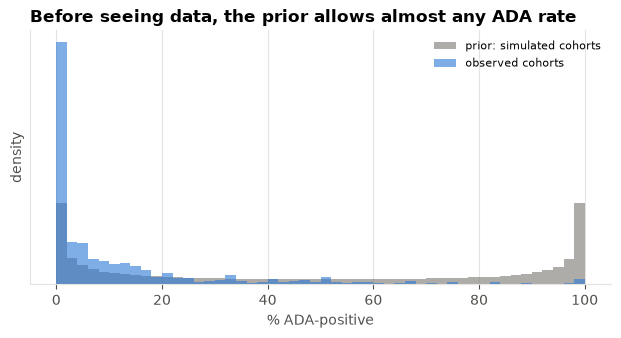

share of prior-simulated cohorts below 1 % or above 99 %: 21%


In [ ]:
pre_all = im.make_preprocessor(scale=True).fit(df)
X_all = pre_all.transform(df)
rng = np.random.default_rng(42)
alpha_prior = rng.normal(0, 1.5, size=500)
beta_prior = rng.normal(0, 1, size=(500, X_all.shape[1]))
p_prior = 1 / (1 + np.exp(-(alpha_prior[:, None] + beta_prior @ X_all.T)))

fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.hist(p_prior.ravel() * 100, bins=50, color=GRAY, alpha=0.7, density=True, label="prior: simulated cohorts")
ax.hist(df["ada_freq"] * 100, bins=50, color=BLUE, alpha=0.6, density=True, label="observed cohorts")
ax.set_xlabel("% ADA-positive"); ax.set_ylabel("density"); ax.set_yticks([])
ax.set_title("Before seeing data, the prior allows almost any ADA rate")
ax.legend(frameon=False, fontsize=8)
fig.savefig(ROOT / "figures" / "bayes_prior_predictive.png"); plt.show()
print(f"share of prior-simulated cohorts below 1 % or above 99 %: {((p_prior < .01) | (p_prior > .99)).mean():.0%}")

With 42 standardised features, Normal(0, 1) priors add up to a wide spread on the logit scale, so many simulated cohorts
sit near 0 % or 100 %. The prior is **weakly informative**: it rules out nothing realistic, and with 211,000 patients
the data will dominate. (A tighter prior is a possible refinement; we keep the plan's prior for transparency.)

## 2 · Fit on all cohorts and check the sampler

**Diagnostics we must see before trusting anything:**
* **r̂ (R-hat) ≈ 1.00** (≤ 1.01): the 4 independent chains agree
* **ESS (effective sample size)** in the hundreds or more: enough independent information in the draws
* **0 divergences**: the sampler didn't hit regions it couldn't explore

In [ ]:
pre_bin, samples_bin, idata_bin = im.fit_bayes(df, kind="binomial")
summ = az.summary(idata_bin, var_names=["alpha", "beta"])
n_div = int(idata_bin.sample_stats.diverging.sum())
print(f"max r_hat = {summ.r_hat.max():.3f} | min bulk ESS = {summ.ess_bulk.min():.0f} | min tail ESS = {summ.ess_tail.min():.0f} | divergences = {n_div}")
assert summ.r_hat.max() <= 1.01 and n_div == 0, "sampler problems: do not trust these results"

max r_hat = 1.000 | min bulk ESS = 2532 | min tail ESS = 2612 | divergences = 0


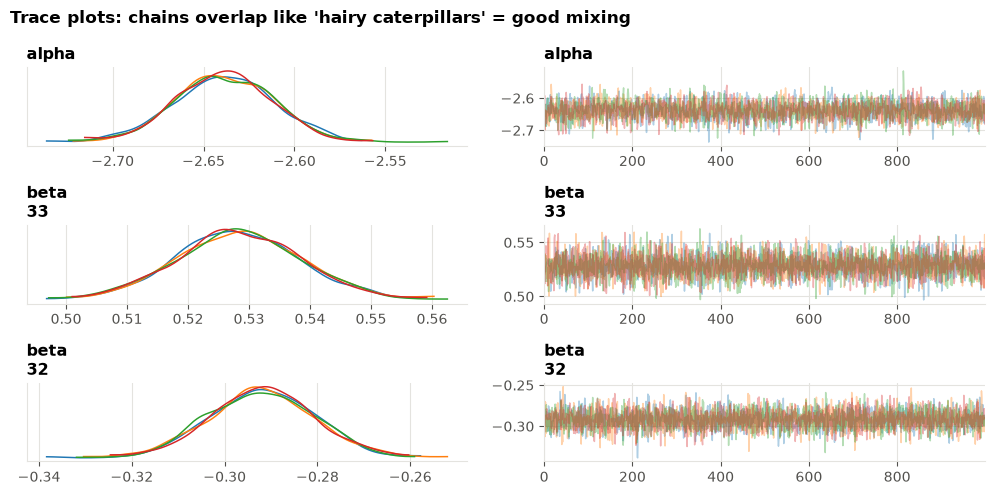

In [ ]:
names = list(pre_bin.get_feature_names_out())
az.plot_trace(idata_bin, var_names=["alpha", "beta"], coords={"beta_dim_0": [names.index("start_year"), names.index("log_dose_mgkg")]},
              compact=False, figsize=(10, 5))
plt.suptitle("Trace plots: chains overlap like 'hairy caterpillars' = good mixing", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "bayes_binomial_trace.png"); plt.show()

## 3 · Posterior odds ratios

How to read the odds ratios: **categories** (route, origin, disease…) are 0/1 columns, so their OR compares the level
with its **reference level** (e.g. chimeric vs humanized). **Numbers and yes/no flags** (dose, start year, follow-up,
co-medication, biosimilar…) are standardised, so their OR is **per 1 SD**. We compare *directions* and *certainty* with
the GLM; the GLM notebook has dose and year in natural units.

In [ ]:
beta_draws = samples_bin["beta"]                                   # (draws, features)
post = pd.DataFrame({
    "OR_mean": np.exp(beta_draws).mean(0),
    "OR_3%": np.exp(np.percentile(beta_draws, 3, axis=0)),
    "OR_97%": np.exp(np.percentile(beta_draws, 97, axis=0)),
    "P(effect > 0)": (beta_draws > 0).mean(0),
}, index=names)
post["94% interval excludes 1"] = (post["OR_3%"] > 1) | (post["OR_97%"] < 1)
print(f"features whose 94 % credible interval excludes OR = 1: {post['94% interval excludes 1'].sum()} of {len(post)}")
display(post.sort_values("OR_mean").style.format({"OR_mean": "{:.2f}", "OR_3%": "{:.2f}", "OR_97%": "{:.2f}", "P(effect > 0)": "{:.2f}"}))

features whose 94 % credible interval excludes OR = 1: 39 of 42


,OR_mean,OR_3%,OR_97%,P(effect > 0),94% interval excludes 1
species_Other,0.14,0.07,0.26,0.00,True
backbone_Human IgG2,0.22,0.21,0.24,0.00,True
route_Ophthalmic,0.27,0.21,0.34,0.00,True
indication_Healthy Volunteer,0.31,0.25,0.39,0.00,True
route_Other,0.43,0.26,0.65,0.00,True
modality_Other,0.46,0.41,0.52,0.00,True
randomized_Not Randomized,0.57,0.52,0.62,0.00,True
modality_Antibody-drug conjugate,0.58,0.50,0.68,0.00,True
backbone_Human IgG4,0.59,0.57,0.62,0.00,True
randomized_Unknown,0.61,0.55,0.68,0.00,True


⚠️ **Almost every interval is very narrow and excludes 1. That is the same over-confidence as the plain GLM's naive
p-values on Day 5.** The Binomial likelihood treats all 211,000 patients as independent coin flips, so it thinks it knows
everything precisely. The data are overdispersed (≈ 22× more spread than Binomial), so these intervals are **too narrow**.
Notebook 08 fixes this with the Beta-Binomial.

## 4 · Grouped CV: point accuracy *and* honesty of the uncertainty

Besides the usual three scores, Bayesian models give a **predictive distribution** for each held-out cohort, so we add:
* **Log predictive score (lps):** log of the probability the model gave to what actually happened, averaged over the posterior (higher = better)
* **90 % interval coverage:** share of held-out cohorts whose observed y falls inside the model's 90 % predictive interval. **An honest model scores ≈ 90 %.**

Each fold refits the model (~30–60 s per fold).

In [ ]:
pred_rows = []
def bayes_binomial(train, test):
    pre, samples, idata = im.fit_bayes(train, kind="binomial")
    s = az.summary(idata, var_names=["alpha", "beta"])
    print(f"  fold fit: max r_hat {s.r_hat.max():.3f}, divergences {int(idata.sample_stats.diverging.sum())}")
    pr = im.bayes_predictive(pre, samples, test)
    pred_rows.append(pd.DataFrame({"cohort_id": test["cohort_id"].values, "lps": pr["lps"], "lo": pr["lo"], "hi": pr["hi"]}))
    return im.predict_bayes(pre, samples, test)

pf, oof = im.cross_validate(df, "fold_grouped", bayes_binomial)
im.save_results("bayes_binomial", pf, oof, df, ROOT)
pred = pd.concat(pred_rows).set_index("cohort_id").loc[df["cohort_id"]].reset_index()
pred.to_csv(ROOT / "results" / "predictive_bayes_binomial.csv", index=False)

inside = (df["y"].values >= pred["lo"].values) & (df["y"].values <= pred["hi"].values)
print("\nBayesian Binomial, grouped CV:", {k: round(v, 4) for k, v in pf.drop(columns="fold").mean().items()})
print(f"mean log predictive score: {pred['lps'].mean():.2f} | 90 % interval coverage: {inside.mean():.1%} (target ≈ 90 %)")

  fold fit: max r_hat 1.000, divergences 0


  fold fit: max r_hat 1.000, divergences 0


  fold fit: max r_hat 1.000, divergences 0


  fold fit: max r_hat 1.000, divergences 0


  fold fit: max r_hat 1.000, divergences 0
Bayesian Binomial, grouped CV: {'wMAE': 0.1602, 'wRMSE': 0.2259, 'loglik': -29.3141}
mean log predictive score: -25.73 | 90 % interval coverage: 47.0% (target ≈ 90 %)


In [ ]:
cv = pd.concat([pd.read_csv(ROOT / "results" / f"cv_{k}.csv") for k in ["naive", "glm_l2", "xgb_default", "bayes_binomial"]])
board = cv.groupby("model")[["wMAE", "wRMSE", "loglik"]].agg(["mean", "std"]).reindex(["naive", "glm_l2", "xgb_default", "bayes_binomial"])
display(board.style.format("{:.3f}"))

## 5 · Picture: honest vs over-confident intervals
A random sample of held-out cohorts: the observed ADA % (dot) and the model's 90 % predictive range (bar).

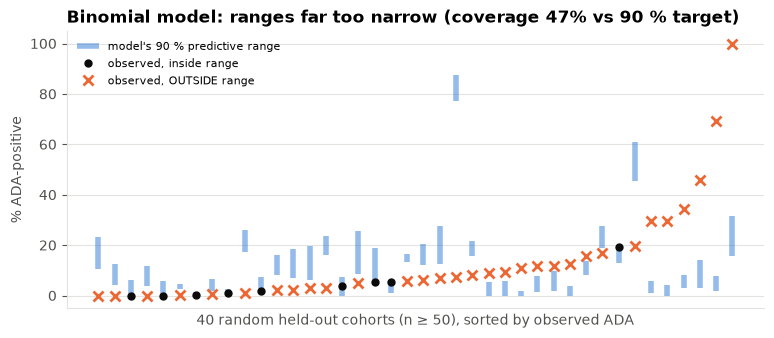

In [ ]:
s = df.assign(lo=pred["lo"].values / df["n"].values, hi=pred["hi"].values / df["n"].values, inside=inside)
s = s[s["n"] >= 50].sample(40, random_state=3).sort_values("ada_freq").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.vlines(s.index, s["lo"] * 100, s["hi"] * 100, color=BLUE, lw=4, alpha=0.5, label="model's 90 % predictive range")
ax.plot(s.index[s.inside], s.loc[s.inside, "ada_freq"] * 100, "o", color="#0b0b0b", ms=5, label="observed, inside range")
ax.plot(s.index[~s.inside], s.loc[~s.inside, "ada_freq"] * 100, "x", color=ORANGE, ms=7, mew=2, label="observed, OUTSIDE range")
ax.set_xticks([]); ax.set_xlabel("40 random held-out cohorts (n ≥ 50), sorted by observed ADA")
ax.set_ylabel("% ADA-positive"); ax.set_title(f"Binomial model: ranges far too narrow (coverage {inside.mean():.0%} vs 90 % target)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig(ROOT / "figures" / "bayes_binomial_coverage.png"); plt.show()

## 6 · Days 8–9 findings (write-up)

1. **The sampler works.** 4 chains × 1,000 draws, max r̂ = 1.00 (≤ 1.01 in every CV fold), bulk ESS > 2,500, **0 divergences**, about 30–60 s per fit. The results can be trusted *as the output of this model*.
2. **The priors are weakly informative.** Simulated from priors alone, cohorts span 0–100 % (21 % of them near the extremes), so the priors exclude nothing realistic and the 211,000 patients dominate.
3. **Same over-confidence as the plain GLM.** 39 of 42 credible intervals exclude OR = 1, very much like the naive GLM p-values (40/42). The Binomial likelihood counts every patient as an independent coin flip, which the data contradict (dispersion ≈ 22).
4. **Prediction for unseen molecules:** wMAE **0.160**, wRMSE 0.226, loglik −29.3. That is essentially the plain GLM (0.161) and **worse than the naive baseline (0.131)**. The N(0, 1) prior is far too weak to regularise against 211,000 "independent" patients.
5. **Uncertainty is dishonest:** the 90 % predictive ranges contain the observed result for only **≈ 47 %** of held-out cohorts (target 90 %), and only 17 % of cohorts with n ≥ 100. The chart shows narrow bars missing most dots.

**Take-away:** being Bayesian doesn't help on its own. **The likelihood has to match the data.** The fix is to let each cohort's true ADA rate vary around the model's prediction: the **Beta-Binomial** (notebook 08).